In [4]:
import math
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
train = (
    pd.read_csv('../Datasets/train.csv')
    .rename(columns={'market_forward_excess_returns': 'target'})
)

# Cast all columns except 'date_id' to float
cols_to_cast = [c for c in train.columns if c != 'date_id']
train[cols_to_cast] = train[cols_to_cast].astype(float)

train

,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V3,V4,V5,V6,V7,V8,V9,forward_returns,risk_free_rate,target
0,0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.002421,0.000301,-0.003038
1,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.008495,0.000303,-0.009114
2,2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.009624,0.000301,-0.010243
3,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.004662,0.000299,0.004046
4,4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.011686,0.000299,-0.012301
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9016,9016,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.208995,0.484788,0.717308,0.677249,-0.327455,0.083995,-0.380452,-0.000015,0.000151,-0.000477
9017,9017,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.082011,0.482804,1.001028,0.596561,-0.372979,0.094246,-0.427355,-0.005199,0.000150,-0.005661
9018,9018,0.0,0.0,0.0,1.0,0.0,-1.0,0.0,0.0,0.0,...,0.334656,0.486772,0.894502,0.656746,-0.282024,0.090608,-0.381337,0.005930,0.000150,0.005467
9019,9019,0.0,0.0,0.0,1.0,0.0,-1.0,0.0,0.0,0.0,...,0.163360,0.492725,1.117639,0.674603,-0.445261,0.106481,-0.477635,0.008173,0.000150,0.007710


## Trend

In [22]:
def plot_moving_average(
    feature,
    window=252,
    center=True,
    min_periods=126,
    title='252-Day Moving Average of Target',
    figsize=(10, 5)
):

    moving_average = feature.rolling(
        window=window,
        center=center,
        min_periods=min_periods
    ).mean()

    ax = feature.plot(style='.', color='0.5', figsize=figsize)
    moving_average.plot(
        ax=ax, linewidth=3, title='252-day moving average of {}'.format(feature.name), legend=False
    )
    plt.show()

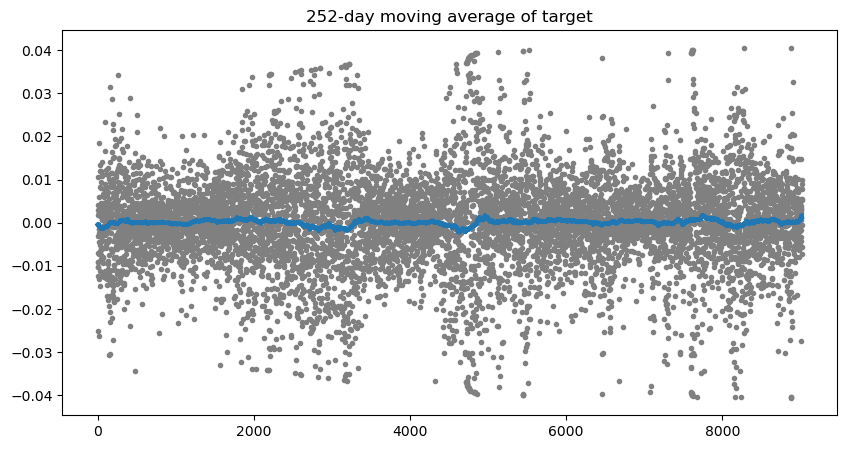

In [23]:
plot_moving_average(train['target'])

In [24]:
print('Annualized volatility of target: {}'.format((train['target'].std() * np.sqrt(252)).round(5)))

Annualized volatility of target: 0.16761


## Seasonality
`date_id`只是交易日，不是日期，所以如果要分析周期性，必须得转换

In [5]:
X = train.copy()

X['week_id'] = X['date_id'] // 5  # week index
X['day_in_week'] = X['date_id'] % 5  # 0-4, position inside week
X['week_in_year'] = X['week_id'] % 51  # week position within each trading year (resets every 51 weeks)

X['bi_weekly_id'] = X['date_id'] // 10  # bi-week index
X['day_in_bi_week'] = X['date_id'] % 10  # 0-9, position inside bi-week
X['bi_week_in_year'] = X['bi_weekly_id'] % 26  # week position within each trading year (resets every 26 weeks)

X['month_id'] = X['date_id'] // 21  # month index
X['day_in_month'] = X['date_id'] % 21  # 0-20, position inside month
X['month_in_year'] = X['month_id'] % 12  # month position within each trading year (resets every 12 months)

X['quarter_id'] = X['date_id'] // 63
X['day_in_quarter'] = X['date_id'] % 63
X['quarter_in_year'] = X['quarter_id'] % 4

X['halfyear_id'] = X['date_id'] // 126
X['day_in_halfyear'] = X['date_id'] % 126
X['half_in_year'] = X['halfyear_id'] % 2

X['year_id'] = X['date_id'] // 252
X['day_in_year'] = X['date_id'] % 252
X['year_in_cycle'] = X['year_id'] % X['year_id'].nunique()

In [6]:
def plot_seasonality(X, target='target', period=None, subperiod=None):
    """
    Captures both intra- and inter-seasonal effects
    """

    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(2, 2, figsize=(18, 10))

    # Intra-period line plot
    sns.lineplot(
        x=period,
        y=target,
        data=X.groupby(period, as_index=False)[target].mean(),
        ax=axes[0, 0],
        marker='o',
    )
    axes[0, 0].set_title(f"Intra-{period.replace('_', ' ').title()} Seasonality", fontsize=12)
    axes[0, 0].set_xlabel(period.replace('_', ' ').title())
    axes[0, 0].set_ylabel(f"Mean {target.title()}")

    # Heatmap of intra-period stability per year
    pivot1 = X.pivot_table(values=target, index='year_id', columns=period, aggfunc='mean')
    sns.heatmap(pivot1, cmap='coolwarm', center=0, ax=axes[0, 1])
    axes[0, 1].set_title(f"{period.replace('_', ' ').title()} Pattern", fontsize=12)
    axes[0, 1].set_xlabel(period.replace('_', ' ').title())
    axes[0, 1].set_ylabel('year_id'.replace('_', ' ').title())

    # Inter-period line plot
    sns.lineplot(
        x=subperiod,
        y=target,
        data=X.groupby(subperiod, as_index=False)[target].mean(),
        ax=axes[1, 0],
        marker='o',
    )
    axes[1, 0].set_title(f"Inter-{subperiod.replace('_', ' ').title()} Seasonality", fontsize=12)
    axes[1, 0].set_xlabel(subperiod.replace('_', ' ').title())
    axes[1, 0].set_ylabel(f"Mean {target.title()}")

    # Heatmap of inter-period stability per year
    pivot2 = X.pivot_table(values=target, index='year_id', columns=subperiod, aggfunc='mean')
    sns.heatmap(pivot2, cmap='coolwarm', center=0, ax=axes[1, 1])
    axes[1, 1].set_title(f"{subperiod.replace('_', ' ').title()} Pattern", fontsize=12)
    axes[1, 1].set_xlabel(subperiod.replace('_', ' ').title())
    axes[1, 1].set_ylabel('year_id'.replace('_', ' ').title())

    plt.tight_layout()
    plt.show()

### Weekly
The top plots show the 3rd and 5th trading day in each cycle outperforms others.  
I can capture this by using **seasonal indicators (one-hot encoding days)**  
Bottom 2 plots are much noisier and less consistent.

29th week / 4.2 trading weeks per month = 6.9th month

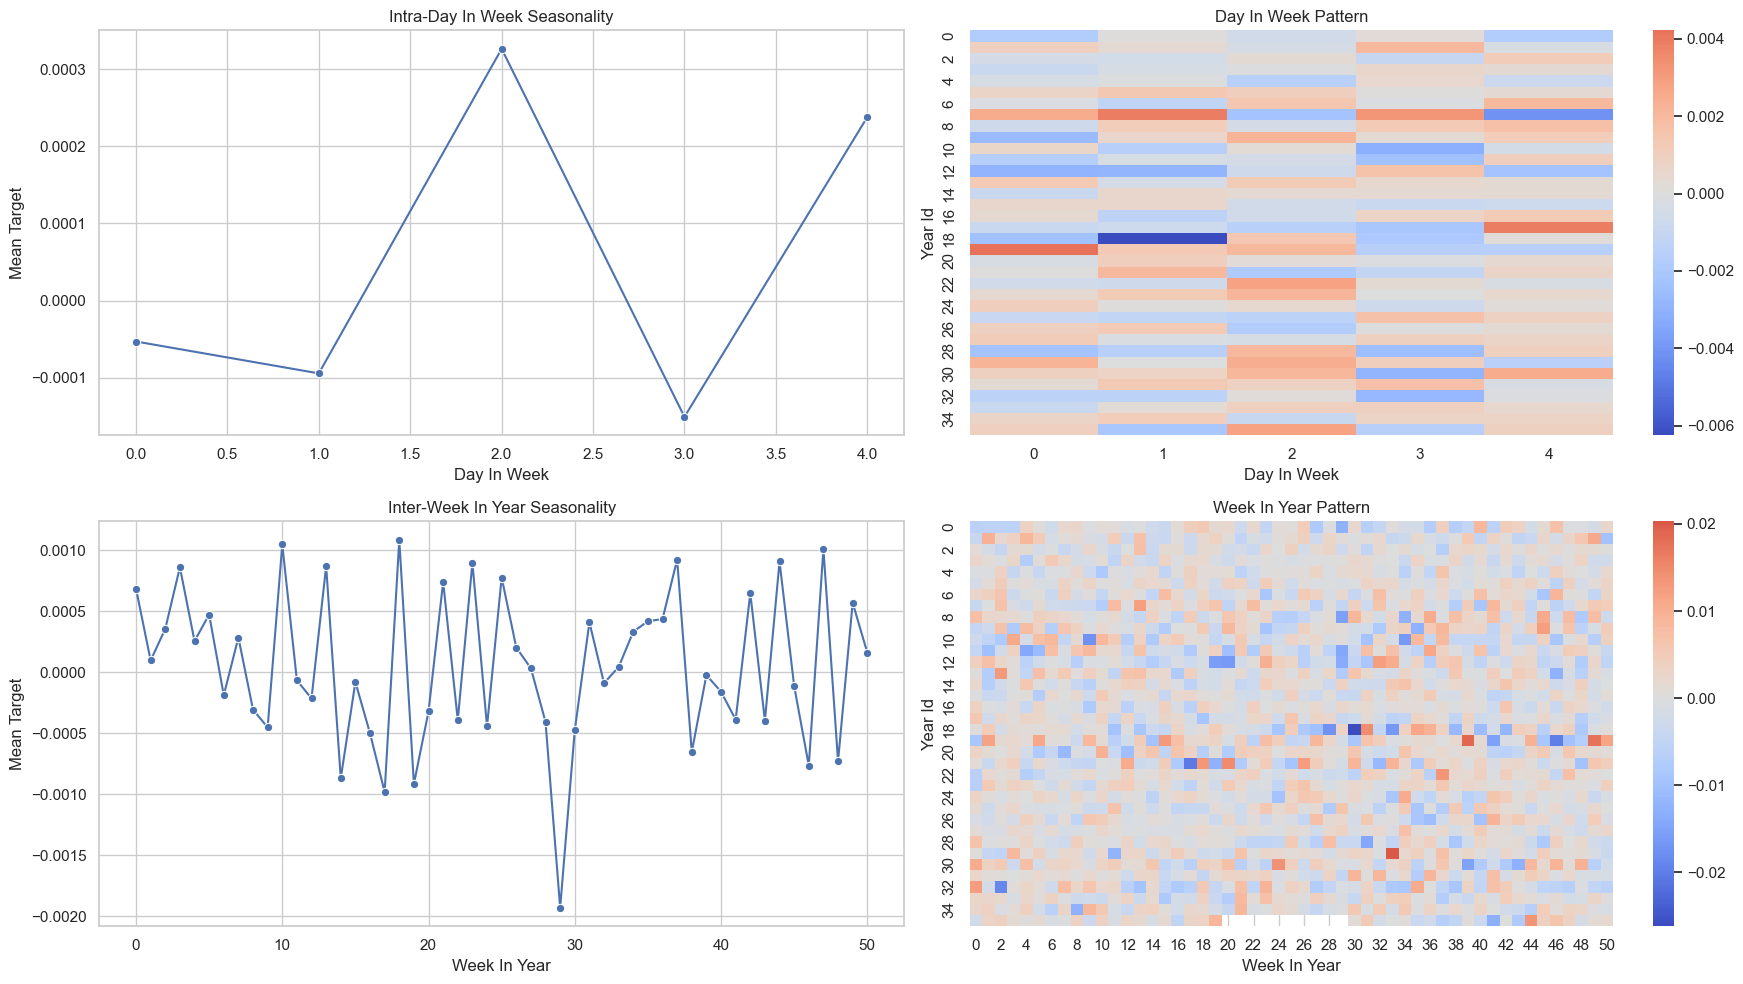

In [7]:
plot_seasonality(
    X,
    period='day_in_week',
    subperiod='week_in_year'
)

### Bi-Weekly 

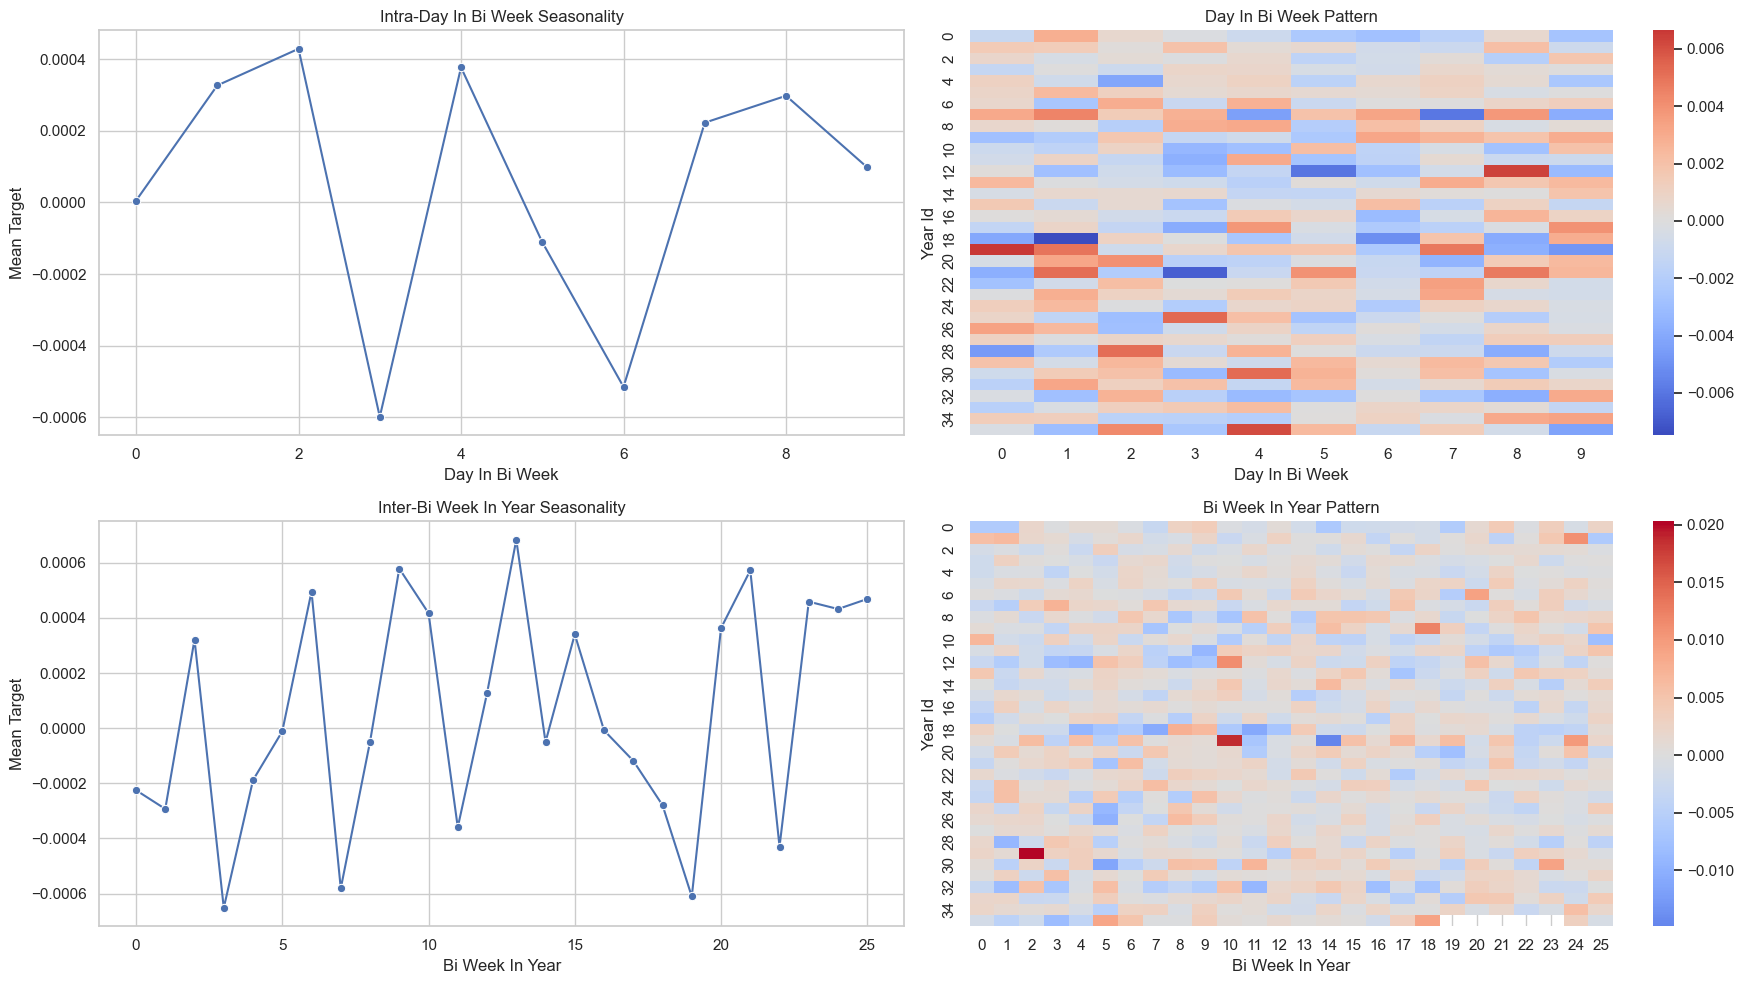

In [8]:
plot_seasonality(
    X,
    period='day_in_bi_week',
    subperiod='bi_week_in_year'
)

### Monthly
Top plots show strong start-of-month effect, graudual weakening mid-month, and end-of-month rebound.

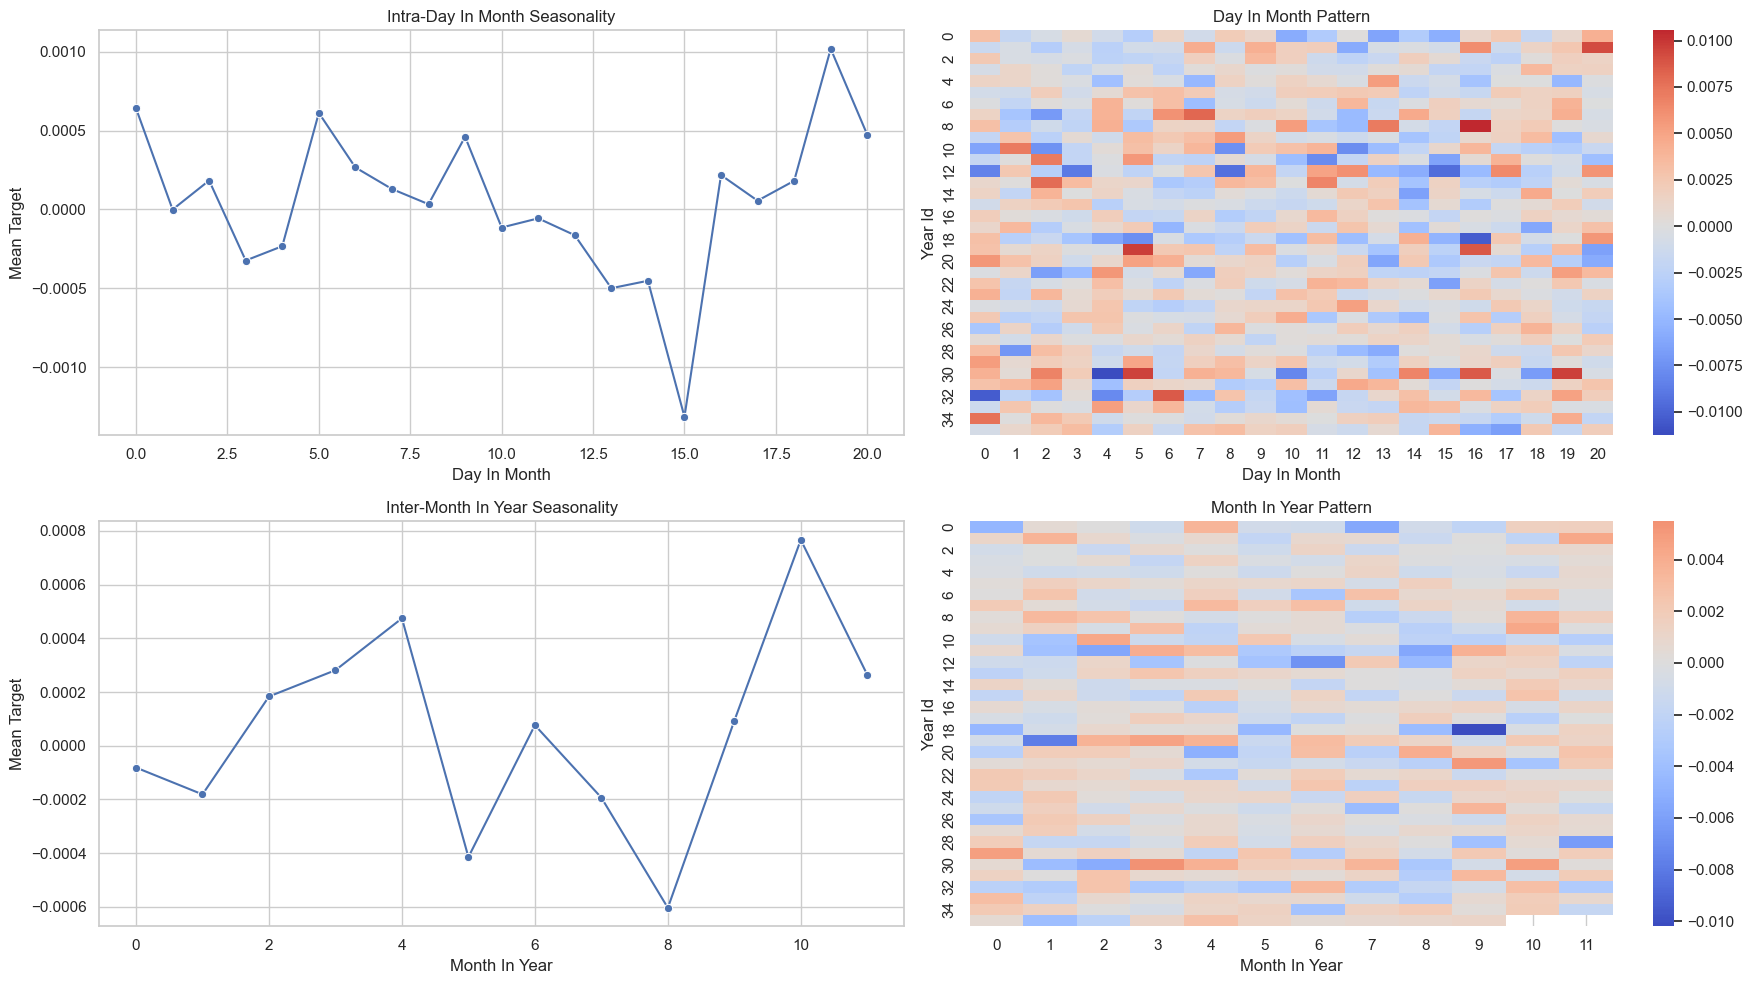

In [9]:
plot_seasonality(
    X,
    period='day_in_month',
    subperiod='month_in_year'
)

### Quarterly
Now, the top 2 plots are not very useful. It's very noisy, with alternating small peaks and dips.  
The bottom 2 plots show that in a year, Q1–Q2 rise slightly, Q3 drops, and Q4 rises the most.

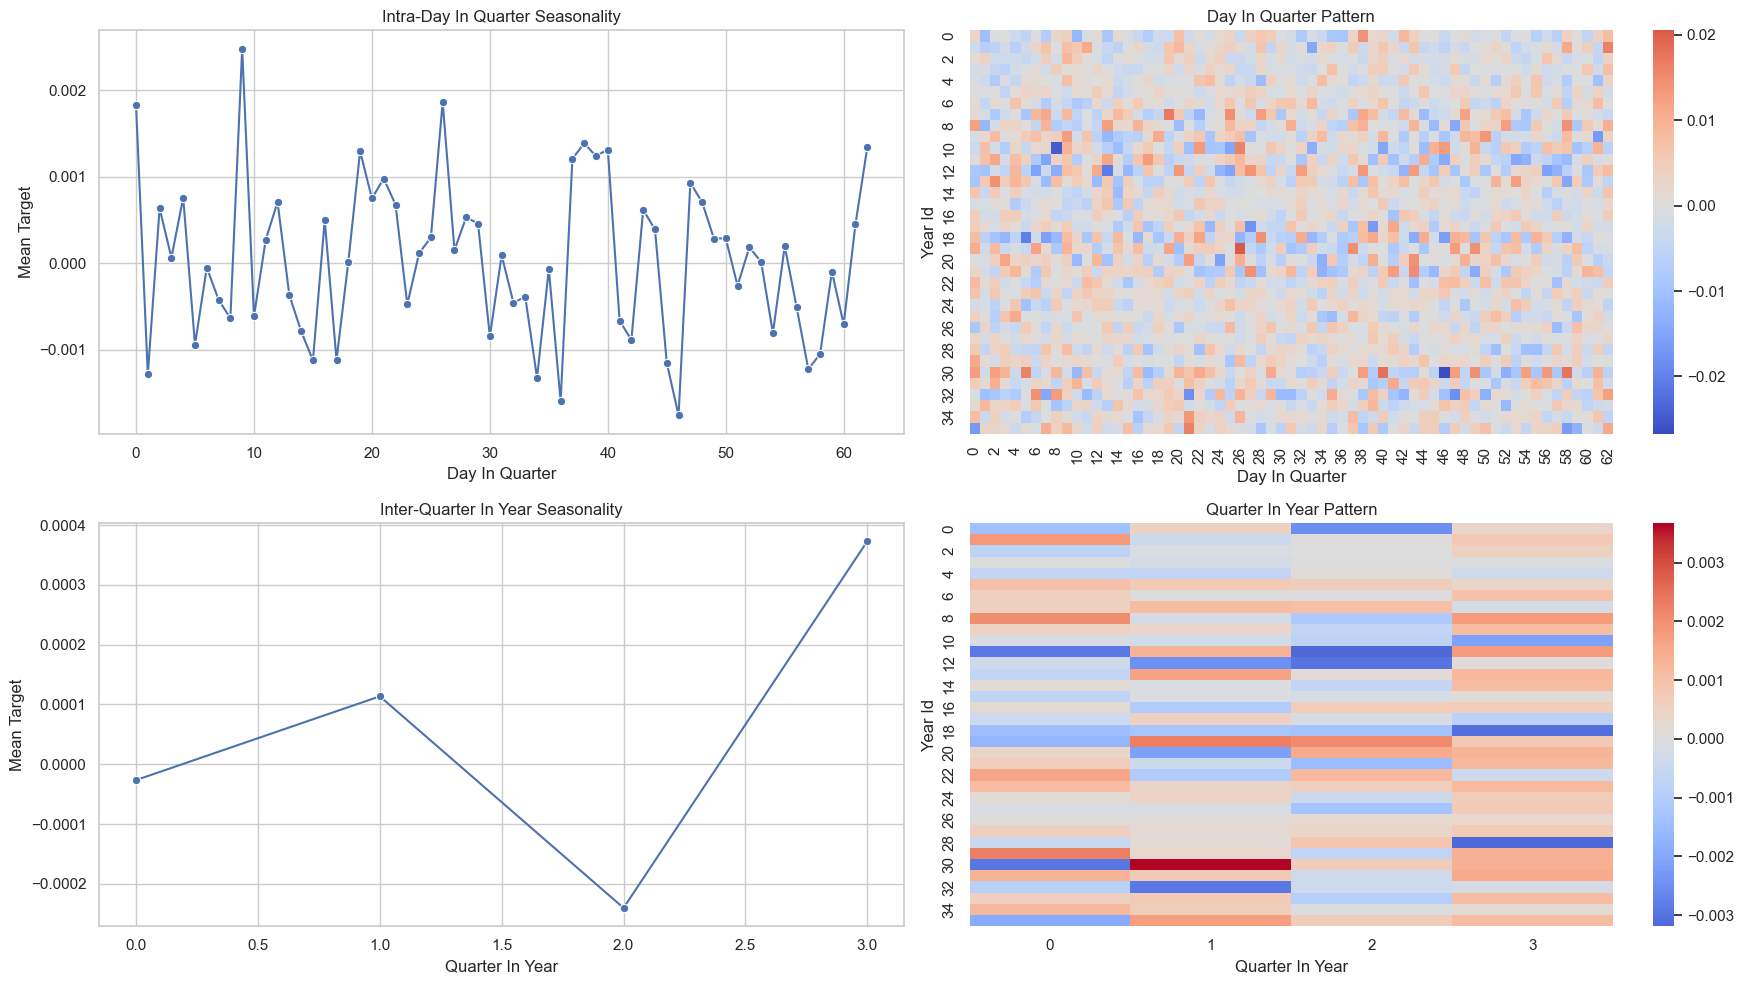

In [10]:
plot_seasonality(
    X,
    period='day_in_quarter',
    subperiod='quarter_in_year'
)

### Semi-Annual
H2 is generally redder than H1 across years in heatmap, which is consistent with the quarterly findings.

In [ ]:
plot_seasonality(
    X,
    period='day_in_halfyear',
    subperiod='half_in_year'
)

### Annual
Top plots are noisy, which confirms that intra-year seasonality (specific days of the year being “stronger”) is very weak.  
But the bottom plots are great at regime detection (e.g. sudden swings in the signs and magnitude)

In [ ]:
plot_seasonality(
    X,
    period='day_in_year',
    subperiod='year_in_cycle'
)

### Periodogram

In [18]:
from scipy.signal import periodogram

def compute_periodogram(ts, detrend='constant'):
    fs = 252
    ts = ts.dropna()
    freq, power = periodogram(ts, fs=fs, detrend=detrend, window='hann', scaling='spectrum')
    return freq, power

In [19]:
freq, power = compute_periodogram(train['target'])

In [20]:
pd.Series(power, index=freq).sort_values(ascending=False).head(10)

123.835052    5.188298e-07
61.735949     4.056282e-07
123.862986    3.645626e-07
18.548720     3.042843e-07
61.763884     2.780053e-07
96.347190     2.768890e-07
77.630861     2.740643e-07
62.965081     2.733298e-07
113.778517    2.695744e-07
77.910210     2.689240e-07
dtype: float64

In [21]:
bands = {
    'Annual': (0, 1.5),
    'Semi-Annual': (1.5, 3),
    'Quarterly': (3, 8),
    'Monthly': (8, 15),
    'Bi-weekly': (15, 35),
    'Weekly': (35, 60),
    'High-Frequence Noise': (60, 126)
}

band_power = {
    name: power[(freq >= low) & (freq < high)].sum()
    for name, (low, high) in bands.items()
}
band_power_share = pd.Series(band_power) / power.sum() * 100
band_power_share.sort_values(ascending=False)

High-Frequence Noise    56.894847
Weekly                  18.275009
Bi-weekly               15.552268
Monthly                  4.618840
Quarterly                2.965710
Semi-Annual              0.862170
Annual                   0.831156
dtype: float64

The periodogram shows that the target is mostly high-frequency noise, with only weekly and bi-weekly cycles being meaningful.  
Therefore, time-based seasonal features with long periods (quarterly, annual) are unlikely to help if applied to the target directly.

## Serial Dependent Features (Cycles)

### Lag Plots

In [ ]:
lags = range(1, 22)
fig, axes = plt.subplots(7, 3, figsize=(16, 18))

y = train['target']
for ax, lag in zip(axes.flatten(), lags):
    corr = y.autocorr(lag)
    pd.plotting.lag_plot(train['target'], lag=lag, ax=ax)
    ax.set_title('Lag {} \n correlation = {:.3f}'.format(lag, corr))

plt.tight_layout()
plt.show()

The lag plots and correlations of target and its 21 lags show no linear relationships, just white noise centered around 0.  
No momentum or mean-reversion. The target behaves like a random walk.  
What if we take the absolute value of the target? So we are looking at the **magnitude** of the returns, not the **direction**.

In [ ]:
lags = range(1, 22)
fig, axes = plt.subplots(7, 3, figsize=(16, 18))

y = abs(train['target'])
for ax, lag in zip(axes.flatten(), lags):
    corr = y.autocorr(lag)
    pd.plotting.lag_plot(y, lag=lag, ax=ax, s=3, alpha=0.6)
    ax.set_title('Lag {} (|target|)\n correlation = {:.3f}'.format(lag, corr))

plt.tight_layout()
plt.show()

Squaring the target also removes signs, but it exaggerates the effect of large moves.

In [ ]:
lags = range(1, 22)
fig, axes = plt.subplots(7, 3, figsize=(16, 18))

y = np.power(train['target'], 2)
for ax, lag in zip(axes.flatten(), lags):
    corr = y.autocorr(lag)
    pd.plotting.lag_plot(y, lag=lag, ax=ax, s=3, alpha=0.6)
    ax.set_title('Lag {} (target ^ 2)\n correlation = {:.3f}'.format(lag, corr))

plt.tight_layout()
plt.show()

The cloud dense near origin means that most days are low-volatility.  
Squaring the target and taking its absolute value, ploting against its lags both show volatility clustering: persistence in magnitude of returns.

In [ ]:
rolling_window = range(2, 6)
lags = range(1, 6)

for window_size in rolling_window:
    y = train['target'].rolling(window=window_size).mean().dropna()
    y_nonoverlap = y.iloc[::window_size]   # take every 'window_size'-th element to remove overlap
    for lag in lags:
        corr = y_nonoverlap.autocorr(lag)
        print('Window={}, Lag={}, Corr={:.3f}'.format(window_size, lag, corr))

Window size matters here because too long window averages over more samples, smoothens volatility changes.  
A smooth series naturally exhibits high correlation between adjacent points because it changes only gradually.

In [ ]:
# SMA
rolling_window = range(2, 6)
lags = range(1, 6)

for window_size in rolling_window:
    y = train['target'].rolling(window=window_size).std().dropna()
    y_nonoverlap = y.iloc[::window_size]   # take every 'window_size'-th element to remove overlap
    for lag in lags:
        corr = y_nonoverlap.autocorr(lag)
        print('Window={}, Lag={}, Corr={:.3f}'.format(window_size, lag, corr))

In [ ]:
# EWMA
# Overlap is always present because every new value depends on all past values (via recursive smoothing)
# So we remove the slicing
# Also, the length of the span directly affects the smoothing factor
rolling_window = range(2, 6)
lags = range(1, 6)

for window_size in rolling_window:
    y = train['target'].ewm(span=window_size).std().dropna()
    for lag in lags:
        corr = y.autocorr(lag)
        print('Window={}, Lag={}, Corr={:.3f}'.format(window_size, lag, corr))

Average returns from one block to the next are basically uncorrelated.  
This means that the “memory” in returns is effectively zero — which matches decades of empirical research on equity indices.  
Directional returns are not predictable from the past, only the magnitude of returns may have persistence.

### Use Partial Autocorrelation to Confirm

In [ ]:
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(train['target'], lags=20)
plt.title('PACF of Raw Target')
plt.show()

In [ ]:
plot_pacf(abs(train['target']), lags=20)
plt.title('PACF of Absolute Target')
plt.show()

In [ ]:
plot_pacf(np.power(train['target'], 2), lags=20)
plt.title('PACF of Target Squared')
plt.show()

In [ ]:
y = train['target'].rolling(window=5).mean().dropna()
y_nonoverlap = y.iloc[::5]

plot_pacf(y_nonoverlap, lags=20)
plt.title('PACF of 5-Day Non-Overlapping Rolling Mean Target')
plt.show()

In [ ]:
y = train['target'].rolling(window=5).std().dropna()
y_nonoverlap = y.iloc[::5] # removes overlap

plot_pacf(y_nonoverlap, lags=20)
plt.title('PACF of 5-Day Non-Overlapping Rolling Std of Target')
plt.show()

In [ ]:
y = train['target'].ewm(span=5).std().dropna()

plot_pacf(y, lags=20)
plt.title('PACF of 5-Day EWMA Rolling Std of Target')
plt.show()

## Feature Engineering Ideas for Target

1. Taking the absolute value of the target and squaring the target are essentially the same, so we choose to take the absolute value and create the lags since it's more robust to outliers
2. Use EWMA for short-term features and SMA for long-term features; compute the z-score or ratio between them
3. Create lag features according to the PACF of SMA and EWMA rolling std
4. Besides these serial-dependent features, the target shows some weekly seasonality and bi-weekly seasonality, so we can create corresponding features for those as well

In [ ]:
def make_lags(ts, lags):
    return pd.concat(
        {
            'target_lag_{}'.format(i): ts.shift(i)
            for i in range(1, lags + 1)
        },
        axis = 1)